<a href="https://colab.research.google.com/github/SriVarshiniD/NIE-ML2/blob/main/ML2Lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Learned rule: FrequentBuyer(x)  ->  PremiumCustomer(x)

Round 0: (most general)                                | pos_covered=2  neg_covered=3
Round 1: FrequentBuyer(x)                              | pos_covered=2  neg_covered=0


/tmp/ipykernel_2824/433866562.py:245: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


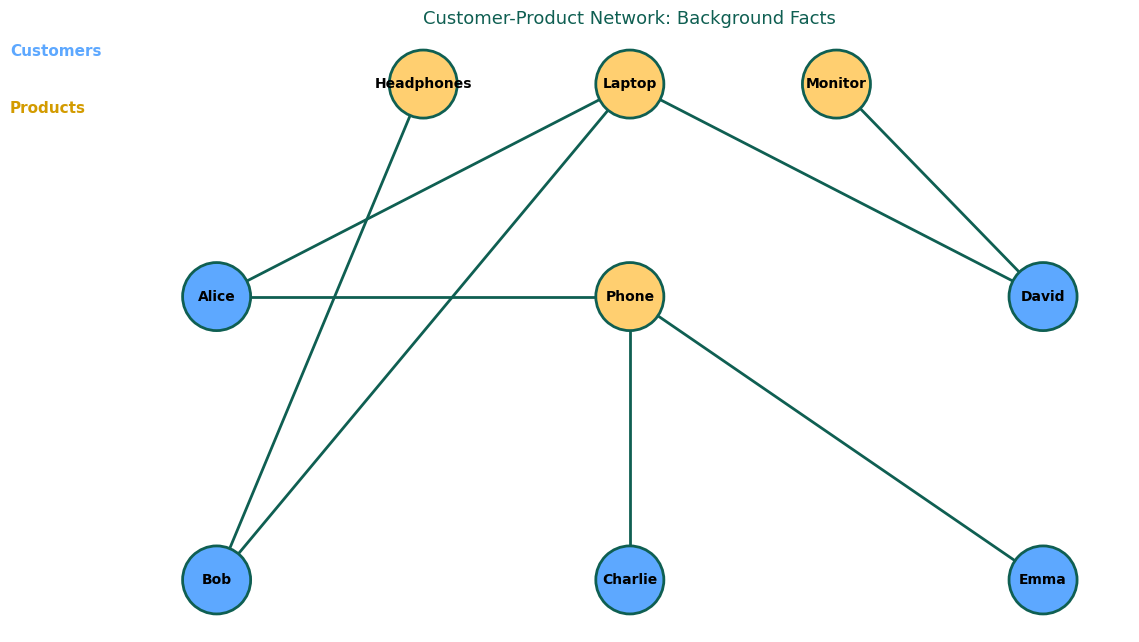

/tmp/ipykernel_2824/433866562.py:326: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


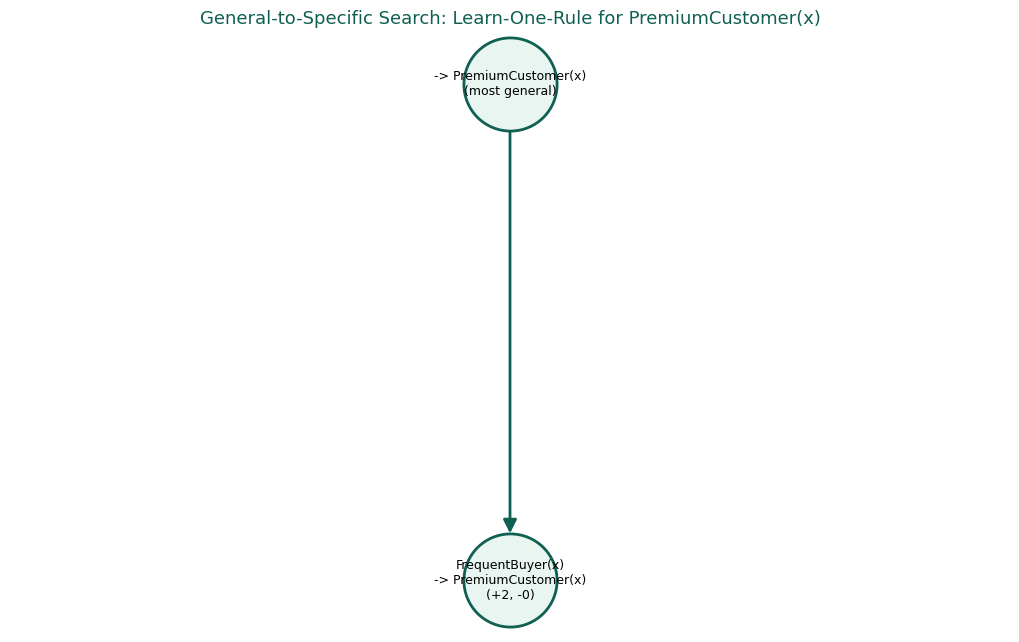

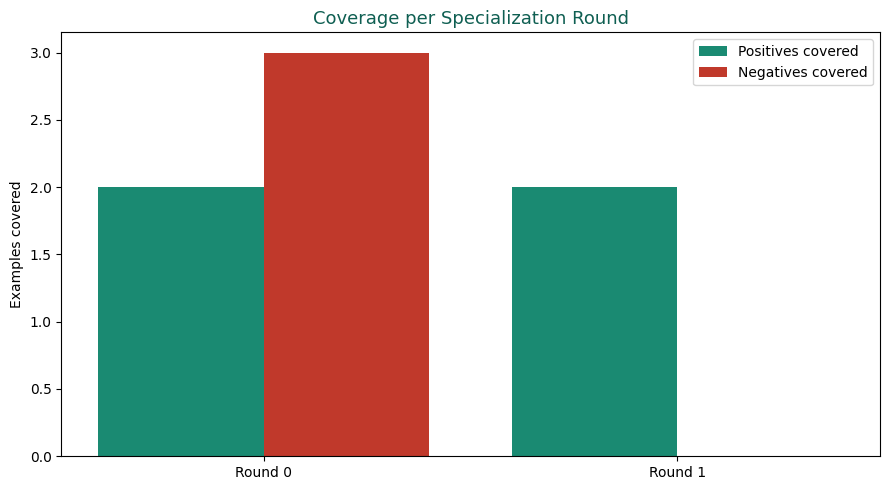

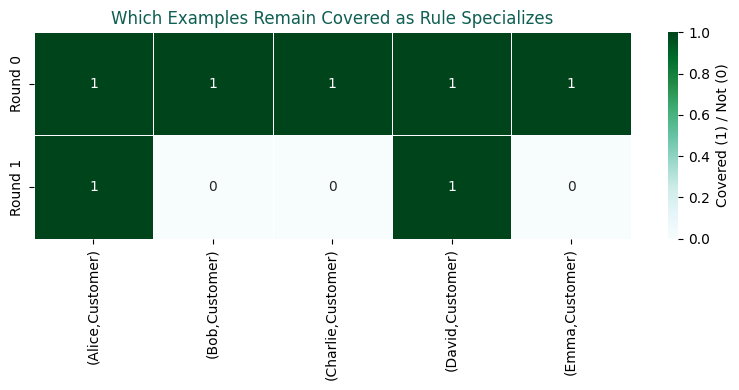


Final learned rule: FrequentBuyer(x)  ->  PremiumCustomer(x)

Verification against training data:
           Instance FrequentBuyer(x) Rule Result Class
  (Alice, Customer)                T     Covered     +
    (Bob, Customer)                F Not covered     -
(Charlie, Customer)                F Not covered     -
  (David, Customer)                T     Covered     +
   (Emma, Customer)                F Not covered     -


In [ ]:
!pip install networkx matplotlib pandas seaborn -q

import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ============================================================
# 1. DATA - Customer relationships/attributes
#    New dataset: Learning "PremiumCustomer(x)"
# ============================================================
facts = {
    "Purchased": {
        ("Alice", "Laptop"),
        ("Alice", "Phone"),
        ("Bob", "Laptop"),
        ("Bob", "Headphones"),
        ("Charlie", "Phone"),
        ("David", "Laptop"),
        ("David", "Monitor"),
        ("Emma", "Phone"),
    },

    "HighSpender": {
        ("Alice",),
        ("David",),
        ("Emma",),
    },

    "Member": {
        ("Alice",),
        ("Bob",),
        ("David",),
    },

    "FrequentBuyer": {
        ("Alice",),
        ("David",),
    },
}

# Training examples
# (customer, target, class)
examples = [
    ("Alice",   "Customer", True),
    ("Bob",     "Customer", False),
    ("Charlie", "Customer", False),
    ("David",   "Customer", True),
    ("Emma",    "Customer", False),
]

# Candidate literals for learning
candidate_literals = {
    "HighSpender(x)": lambda x, y: (x,) in facts["HighSpender"],
    "Member(x)": lambda x, y: (x,) in facts["Member"],
    "FrequentBuyer(x)": lambda x, y: (x,) in facts["FrequentBuyer"],
    "Purchased(x,Laptop)": lambda x, y: (x, "Laptop") in facts["Purchased"],
    "Purchased(x,Phone)": lambda x, y: (x, "Phone") in facts["Purchased"],
}

# ============================================================
# 2. LEARN-ONE-FIRST-ORDER-RULE
#    General-to-specific search
# ============================================================
def evaluate_rule(literal_names, examples):
    pos, neg, covered = 0, 0, []

    for x, y, label in examples:
        satisfied = all(
            candidate_literals[lit](x, y)
            for lit in literal_names
        )

        if satisfied:
            covered.append((x, y, label))

            if label:
                pos += 1
            else:
                neg += 1

    return pos, neg, covered


def learn_one_rule(examples, candidate_literals):
    rule_body = []
    history = []
    round_num = 0

    while True:

        pos, neg, covered = evaluate_rule(
            rule_body,
            examples
        )

        history.append({
            "round": round_num,
            "rule": " AND ".join(rule_body)
                    if rule_body
                    else "(most general)",
            "pos_covered": pos,
            "neg_covered": neg,
        })

        # Stop when no negative examples are covered
        if neg == 0:
            break

        scores = {}

        for lit in candidate_literals:

            if lit in rule_body:
                continue

            trial_body = rule_body + [lit]

            p, n, _ = evaluate_rule(
                trial_body,
                examples
            )

            scores[lit] = (p - n, p, n)

        # Select the literal with the best score
        best_lit = max(
            scores,
            key=lambda l: scores[l][0]
        )

        rule_body.append(best_lit)
        round_num += 1

    final_pos, final_neg, final_covered = evaluate_rule(
        rule_body,
        examples
    )

    return rule_body, history, final_covered


# Learn the rule
rule_body, history, final_covered = learn_one_rule(
    examples,
    candidate_literals
)

rule_str = (
    " AND ".join(rule_body)
    + "  ->  PremiumCustomer(x)"
)

print("Learned rule:", rule_str)
print()

for h in history:
    print(
        "Round {}: {:45s} | pos_covered={}  neg_covered={}".format(
            h["round"],
            h["rule"],
            h["pos_covered"],
            h["neg_covered"]
        )
    )


# ============================================================
# 3. VISUALIZATION 1 - Customer/Product Network
# ============================================================
G_customer = nx.Graph()

# Add customer-product relationships
for customer, product in facts["Purchased"]:
    G_customer.add_edge(customer, product)

# Positions
pos_customer = {
    "Alice": (-2, 1),
    "Bob": (-2, -1),
    "Charlie": (0, -1),
    "David": (2, 1),
    "Emma": (2, -1),

    "Laptop": (0, 2.5),
    "Phone": (0, 1),
    "Headphones": (-1, 2.5),
    "Monitor": (1, 2.5),
}

customer_color = "#5da8ff"
product_color = "#ffcf70"

node_colors = []

for n in G_customer.nodes():

    if n in ["Alice", "Bob", "Charlie", "David", "Emma"]:
        node_colors.append(customer_color)
    else:
        node_colors.append(product_color)


plt.figure(figsize=(10, 6))

nx.draw(
    G_customer,
    pos_customer,
    with_labels=True,
    node_size=2400,
    node_color=node_colors,
    edgecolors="#0f5f52",
    linewidths=2,
    font_size=10,
    font_weight="bold",
    edge_color="#0f5f52",
    width=2
)

plt.title(
    "Customer-Product Network: Background Facts",
    fontsize=13,
    color="#0f5f52"
)

plt.text(
    -3,
    2.7,
    "Customers",
    color=customer_color,
    fontsize=11,
    fontweight="bold"
)

plt.text(
    -3,
    2.3,
    "Products",
    color="#d39b00",
    fontsize=11,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()


# ============================================================
# 4. VISUALIZATION 2 - Search Lattice
#    General -> Specific
# ============================================================
G = nx.DiGraph()

node_labels = {}

prev_node = "root"

G.add_node(prev_node)

node_labels[prev_node] = (
    "-> PremiumCustomer(x)\n"
    "(most general)"
)

for i, h in enumerate(history[1:], start=1):

    node = "step{}".format(i)

    G.add_node(node)
    G.add_edge(prev_node, node)

    node_labels[node] = (
        "{}\n"
        "-> PremiumCustomer(x)\n"
        "(+{}, -{})"
    ).format(
        h["rule"],
        h["pos_covered"],
        h["neg_covered"]
    )

    prev_node = node


plt.figure(figsize=(10, 6))

pos = {
    n: (0, -i)
    for i, n in enumerate(G.nodes())
}

nx.draw(
    G,
    pos,
    with_labels=False,
    node_size=4500,
    node_color="#e8f5f0",
    edgecolors="#0f5f52",
    linewidths=2,
    arrows=True,
    arrowsize=20,
    edge_color="#0f5f52",
    width=2
)

for n, (px, py) in pos.items():

    plt.text(
        px,
        py,
        node_labels[n],
        ha="center",
        va="center",
        fontsize=9
    )

plt.title(
    "General-to-Specific Search: "
    "Learn-One-Rule for PremiumCustomer(x)",
    fontsize=13,
    color="#0f5f52"
)

plt.axis("off")
plt.tight_layout()
plt.show()


# ============================================================
# 5. VISUALIZATION 3 - Per-round Coverage Bars
# ============================================================
rounds = [
    h["round"]
    for h in history
]

pos_vals = [
    h["pos_covered"]
    for h in history
]

neg_vals = [
    h["neg_covered"]
    for h in history
]

x_idx = range(len(rounds))

plt.figure(figsize=(9, 5))

plt.bar(
    [i - 0.2 for i in x_idx],
    pos_vals,
    width=0.4,
    label="Positives covered",
    color="#1a8a72"
)

plt.bar(
    [i + 0.2 for i in x_idx],
    neg_vals,
    width=0.4,
    label="Negatives covered",
    color="#c0392b"
)

plt.xticks(
    list(x_idx),
    ["Round {}".format(r) for r in rounds]
)

plt.ylabel("Examples covered")

plt.title(
    "Coverage per Specialization Round",
    fontsize=13,
    color="#0f5f52"
)

plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 6. VISUALIZATION 4 - Coverage Evolution Heatmap
#    Examples x Rounds
# ============================================================
example_ids = [
    "({},{})".format(x, y)
    for x, y, _ in examples
]

heat_data = []

for h_i in range(len(history)):

    body = rule_body[:h_i]

    row = []

    for x, y, label in examples:

        satisfied = all(
            candidate_literals[lit](x, y)
            for lit in body
        )

        row.append(
            1 if satisfied else 0
        )

    heat_data.append(row)


heat_df = pd.DataFrame(
    heat_data,
    index=[
        "Round {}".format(h["round"])
        for h in history
    ],
    columns=example_ids
)


plt.figure(figsize=(8, 4))

sns.heatmap(
    heat_df,
    annot=True,
    cmap="BuGn",
    cbar_kws={
        "label": "Covered (1) / Not (0)"
    },
    linewidths=0.5,
    linecolor="white"
)

plt.title(
    "Which Examples Remain Covered "
    "as Rule Specializes",
    fontsize=12,
    color="#0f5f52"
)

plt.tight_layout()
plt.show()


# ============================================================
# 7. FINAL VERIFICATION TABLE
# ============================================================
print()

print(
    "Final learned rule:",
    rule_str
)

print()

print(
    "Verification against training data:"
)

verify_rows = []

for x, y, label in examples:

    lit_results = {
        lit: candidate_literals[lit](x, y)
        for lit in rule_body
    }

    satisfied = all(
        lit_results.values()
    )

    row = {
        "Instance": "({}, {})".format(x, y)
    }

    for lit, val in lit_results.items():

        row[lit] = (
            "T"
            if val
            else "F"
        )

    row["Rule Result"] = (
        "Covered"
        if satisfied
        else "Not covered"
    )

    row["Class"] = (
        "+"
        if label
        else "-"
    )

    verify_rows.append(row)


verify_df = pd.DataFrame(
    verify_rows
)

print(
    verify_df.to_string(
        index=False
    )
)
